[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jinming99/learn-ml-by-building/blob/main/Lecture%2011%20K-Means/11-KMeans.ipynb)

# Lecture 11: K-Means Clustering

Suppose we have a pile of documents and no labels. Which ones belong together?
K-means gives us a precise answer to a narrower question: which groups keep
points close to their group means? Whether those groups are useful is still ours to judge.

We'll follow three ideas: how assignment and averaging reduce an objective,
why the starting point matters, and how to tell what a cluster actually represents.

## 1. Which Points Belong Together?

Here are 300 points, with no group labels shown. How many groups would you choose?
What would make one grouping more convincing than another?

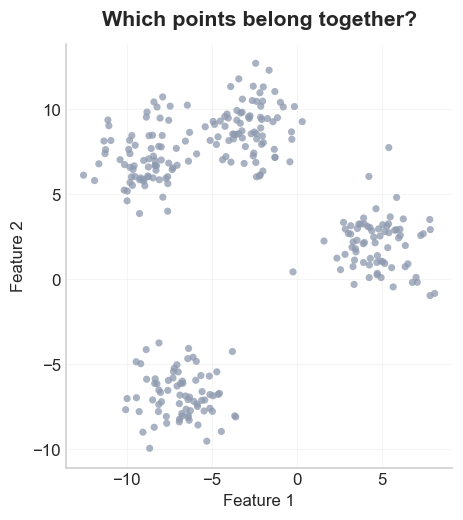

In [50]:
import base64
from html import escape
from io import BytesIO

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator
from IPython.display import HTML, display
from sklearn.cluster import KMeans, kmeans_plusplus
from sklearn.datasets import fetch_20newsgroups, make_blobs, make_moons, make_circles
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import adjusted_rand_score, silhouette_samples, silhouette_score
from threadpoolctl import threadpool_limits

COLORS = np.array(['#3A86FF', '#E76F51', '#2A9D8F', '#9467BD', '#D49A22', '#657786'])
INK, MUTED = '#263238', '#8D99AE'
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11, 'axes.titlesize': 14,
                     'axes.titleweight': 'bold', 'axes.titlepad': 12,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'grid.alpha': .18, 'legend.frameon': False,
                     'animation.embed_limit': 30})


def plot_groups(ax, points, labels=None, centers=None):
    ax.scatter(*points.T, c=MUTED if labels is None else COLORS[labels],
               s=22, alpha=.75, edgecolors='none')
    if centers is not None:
        ax.scatter(*centers.T, c=COLORS[:len(centers)], marker='X', s=160,
                   edgecolors=INK, linewidths=1.3, zorder=5)
    ax.set(xlabel='Feature 1', ylabel='Feature 2', aspect='equal')


def png_data(fig):
    buffer = BytesIO()
    fig.savefig(buffer, format='png', bbox_inches='tight', dpi=120)
    return base64.b64encode(buffer.getvalue()).decode('ascii')


X_simple, toy_source_labels = make_blobs(n_samples=300, centers=4, cluster_std=1.5,
                                       center_box=(-10, 10), random_state=42)
toy_limits = (X_simple.min(axis=0) - 1.5, X_simple.max(axis=0) + 1.5)
fig, ax = plt.subplots(figsize=(8, 5))
plot_groups(ax, X_simple)
ax.set_title('Which points belong together?')
plt.show()

## 2. Assign. Average. Repeat.

Let's choose $k=4$ for now. K-means minimizes the **cost** $J$, the total squared
distance from each point to its assigned center:

$$J(c,\mu)=\sum_{i=1}^{n}\|x_i-\mu_{c_i}\|^2.$$

With the centers fixed, assign each point to the nearest one:
$c_i\leftarrow\arg\min_j\|x_i-\mu_j\|^2$.
With the assignments fixed, move each center to its group's mean:
$\mu_j\leftarrow\frac{1}{|S_j|}\sum_{i\in S_j}x_i$.
Neither step increases $J$. Notice what changes in each step—and what stays fixed.

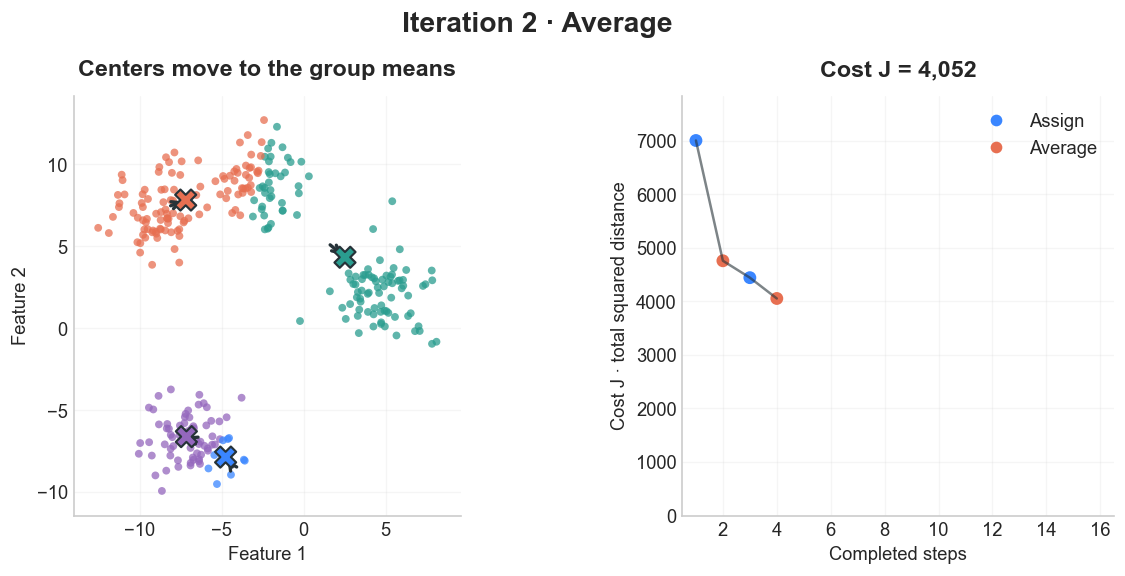

In [51]:
def lloyd_steps(points, k, seed=3, max_iter=30, tol=1e-8):
    centers = points[np.random.default_rng(seed).choice(len(points), k, replace=False)].copy()
    history = []
    for iteration in range(1, max_iter + 1):
        labels = ((points[:, None] - centers) ** 2).sum(axis=2).argmin(axis=1)
        history.append(dict(phase='Assign', iteration=iteration, centers=centers.copy(),
                            labels=labels.copy(), previous=centers.copy(),
                            cost=((points - centers[labels]) ** 2).sum()))
        updated = np.array([points[labels == j].mean(axis=0) if np.any(labels == j)
                            else centers[j] for j in range(k)])
        history.append(dict(phase='Average', iteration=iteration, centers=updated.copy(),
                            labels=labels.copy(), previous=centers.copy(),
                            cost=((points - updated[labels]) ** 2).sum()))
        movement = np.linalg.norm(updated - centers)
        centers = updated  # Keep the update even when it satisfies the stopping rule.
        if movement <= tol:
            break
    # Labels must correspond to the returned centers, even at an iteration limit.
    labels = ((points[:, None] - centers) ** 2).sum(axis=2).argmin(axis=1)
    return labels, centers, history


toy_labels, toy_centers, history = lloyd_steps(X_simple, 4)
animation_fig, (scene, objective) = plt.subplots(1, 2, figsize=(12, 5),
                                              gridspec_kw={'width_ratios': [1.25, 1]})
animation_fig.subplots_adjust(wspace=.3, top=.84, bottom=.14)
costs = np.array([step['cost'] for step in history])


def draw_step(frame):
    step = history[frame]
    scene.clear()
    objective.clear()
    plot_groups(scene, X_simple, step['labels'], step['centers'])
    scene.set(xlim=(toy_limits[0][0], toy_limits[1][0]),
              ylim=(toy_limits[0][1], toy_limits[1][1]))
    scene.set_title('Nearest-center assignments' if step['phase'] == 'Assign'
                    else 'Centers move to the group means')
    if step['phase'] == 'Average':
        for old, new in zip(step['previous'], step['centers']):
            scene.annotate('', xy=new, xytext=old,
                           arrowprops=dict(arrowstyle='->', color=INK, lw=2))
    x_steps = np.arange(1, frame + 2)
    objective.plot(x_steps, costs[:frame + 1], color=INK, lw=1.5, alpha=.6)
    objective.scatter(x_steps, costs[:frame + 1], s=45,
                      c=[COLORS[0] if i % 2 == 1 else COLORS[1] for i in x_steps])
    objective.set(xlim=(.5, len(history) + .5), ylim=(0, costs.max() * 1.12),
                  xlabel='Completed steps', ylabel='Cost J · total squared distance',
                  title=f"Cost J = {step['cost']:,.0f}")
    objective.xaxis.set_major_locator(MaxNLocator(integer=True))
    objective.legend(handles=[Line2D([], [], marker='o', ls='', color=COLORS[0], label='Assign'),
                              Line2D([], [], marker='o', ls='', color=COLORS[1], label='Average')],
                     loc='upper right')
    animation_fig.suptitle(f"Iteration {step['iteration']} · {step['phase']}", fontsize=17, weight='bold')


animation = FuncAnimation(animation_fig, draw_step, frames=len(history), interval=950, repeat=False)
animation_html = animation.to_jshtml(default_mode='once')
draw_step(min(3, len(history) - 1))
preview = png_data(animation_fig)
plt.close(animation_fig)
# HTML plays in a trusted notebook; the PNG is the saved noninteractive fallback.
display({'text/html': animation_html, 'image/png': preview,
         'text/plain': 'K-means: alternating assignments and mean updates.'}, raw=True)

## 3. Does the Starting Point Matter?

Same points, same $k=4$, same assign-and-average updates. Only the starting
centers change. Does every falling cost curve lead to the same final grouping?

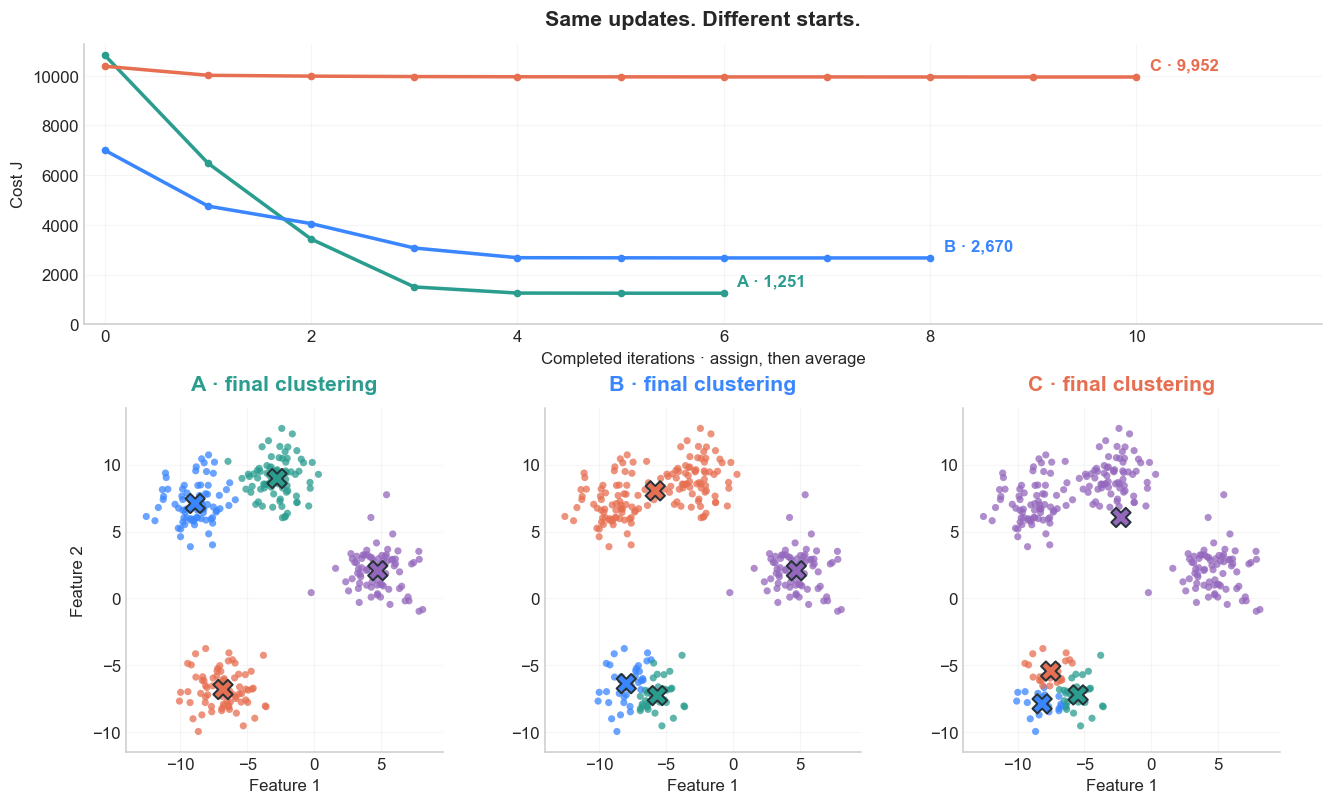

In [52]:
# Fixed seeds selected to illustrate three distinct outcomes, not their frequency.
start_seeds = [11, 3, 14]
start_runs = [lloyd_steps(X_simple, 4, seed=seed) for seed in start_seeds]
run_colors = [COLORS[2], COLORS[0], COLORS[1]]
fig = plt.figure(figsize=(12, 7.2), layout='constrained')
grid = fig.add_gridspec(2, 3, height_ratios=[.9, 1.1])
trajectory = fig.add_subplot(grid[0, :])
for col, (letter, (labels, centers, steps), color) in enumerate(zip('ABC', start_runs, run_colors)):
    # Iteration zero is the initial assignment; then record each complete update.
    run_cost = [steps[0]['cost']] + [step['cost'] for step in steps if step['phase'] == 'Average']
    iterations = np.arange(len(run_cost))
    trajectory.plot(iterations, run_cost, 'o-', color=color, lw=2.3, ms=4)
    trajectory.annotate(f'{letter} · {run_cost[-1]:,.0f}', (iterations[-1], run_cost[-1]),
                        xytext=(9, 5), textcoords='offset points', color=color, weight='bold')
    ax = fig.add_subplot(grid[1, col])
    # Order cluster colors from left to right; numeric cluster IDs have no meaning.
    order = np.argsort(centers[:, 0])
    plot_groups(ax, X_simple, np.argsort(order)[labels], centers[order])
    ax.set(xlim=(toy_limits[0][0], toy_limits[1][0]),
           ylim=(toy_limits[0][1], toy_limits[1][1]))
    ax.set_title(f'{letter} · final clustering', color=color)
    if col:
        ax.set_ylabel('')
trajectory.set(xlabel='Completed iterations · assign, then average', ylabel='Cost J',
               xlim=(-.2, max(len(run[2]) // 2 for run in start_runs) + 1.8), ylim=(0, None),
               title='Same updates. Different starts.')
trajectory.xaxis.set_major_locator(MaxNLocator(integer=True))
plt.show()

All three runs stop improving, but at different costs. Convergence is not a
promise of the best solution. Multiple starts help: later, `n_init=10` keeps
the lowest-cost result from ten complete K-means fits. The default **k-means++**
initialization favors starting centers farther from the ones already chosen;
it improves the odds of a useful start, without guaranteeing the best result.

## 4. The Centers Stopped. Is the Grouping Good?

What makes one of these groupings more convincing than another? We want points
in the same group to be close (**cohesion**) and different groups to be apart
(**separation**). Our cost measures squared distance to group means; it does not
directly measure separation. One center per point would make the cost zero,
but would that be a useful grouping?

**Silhouette** asks how well each point fits its assigned group. Let $a$ be its
average distance to the other points in its own cluster. For each other cluster,
average the distances to all its members; $b$ is the smallest of those averages.
These are point-to-point distances, not distances to centers.

$$s=\frac{b-a}{\max(a,b)}.$$

Near $+1$, its own group is much closer; near $0$, the two average distances are
similar; below $0$, another group is closer on average. The overall score is the
mean over points—no topic labels or answer key needed. Scikit-learn calls our
squared-distance cost *inertia* (`inertia_`); silhouette asks a different question.

**ARI (adjusted Rand index)** compares a grouping with reference labels by asking
which pairs belong together. It corrects for chance: 1 is a perfect match (even
with renamed labels), near 0 is chance-level agreement, and negative values are
possible. Here the reference labels identify each point's source cloud.

Let's separate the two ideas. Moving right pulls the group centers farther apart;
moving down spreads the points within each group. These are controlled synthetic
examples made from the same two point clouds, with identical axes. The two views
show the original groups or a K-means fit to exactly the same points. Every metric
describes the colored grouping; ARI compares it with the original groups.
Only coordinates, never reference labels, enter the fit.

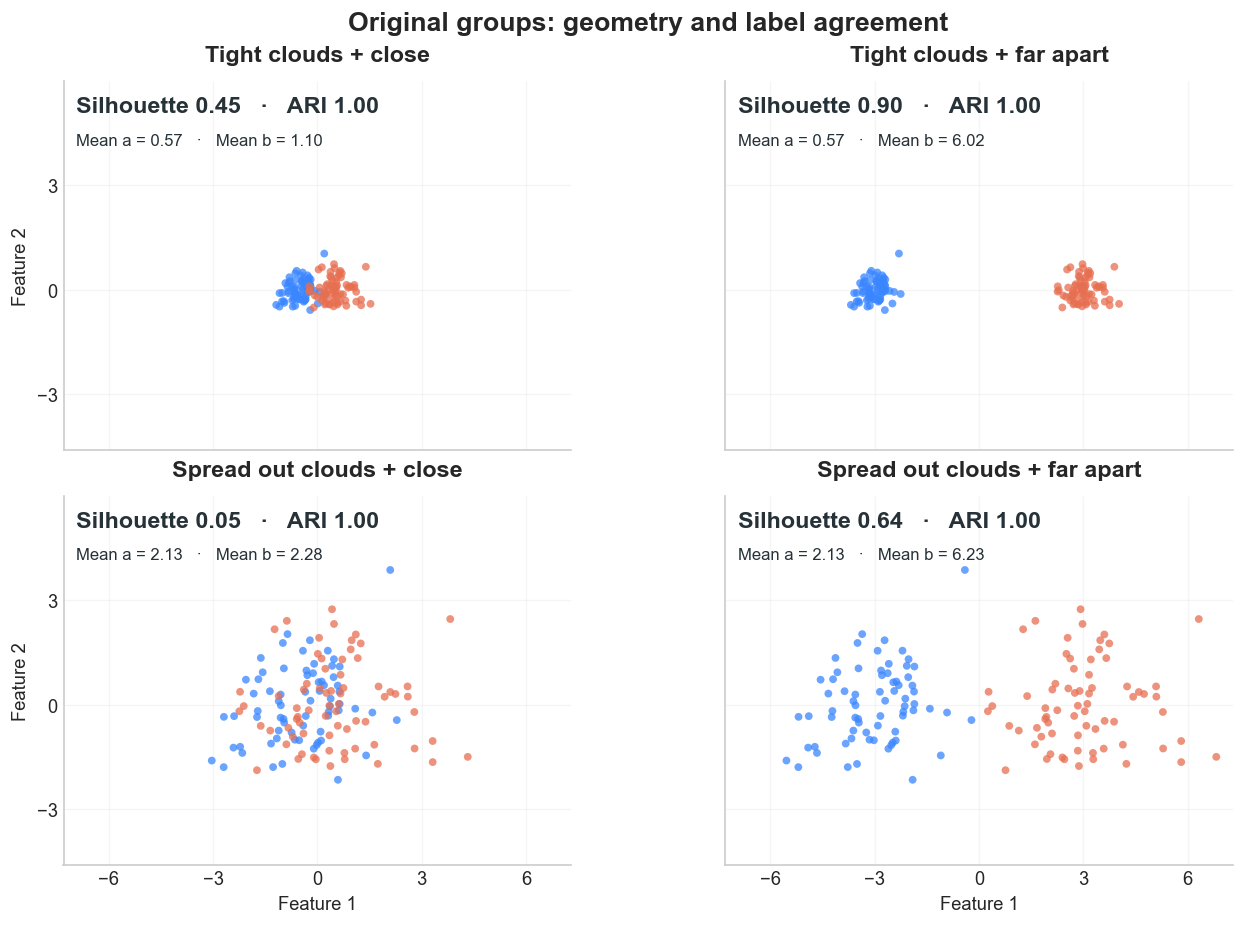

In [53]:
rng = np.random.default_rng(42)
base_clouds = rng.normal(size=(2, 70, 2))
base_clouds -= base_clouds.mean(axis=1, keepdims=True)
example_labels = np.repeat([0, 1], 70)
geometry_views, geometry_previews = {}, []

for view in ['Original groups', 'K-means fit']:
    geometry_views[view] = []
    fig, axes = plt.subplots(2, 2, figsize=(11, 7.6), sharex=True, sharey=True, layout='constrained')
    for row, (spread, cohesion) in enumerate([(.35, 'Tight'), (1.3, 'Spread out')]):
        for col, (gap, separation) in enumerate([(1., 'close'), (6., 'far apart')]):
            offsets = np.array([[[-gap / 2, 0]], [[gap / 2, 0]]])
            points = (spread * base_clouds + offsets).reshape(-1, 2)
            labels = example_labels
            if view == 'K-means fit':
                with threadpool_limits(limits=1):
                    model = KMeans(n_clusters=2, n_init=10, random_state=42).fit(points)
                labels = model.labels_
                # Keep the left center blue; relabeling does not change either score.
                if model.cluster_centers_[0, 0] > model.cluster_centers_[1, 0]:
                    labels = 1 - labels
            same_group = labels[:, None] == labels[None, :]
            distances = np.linalg.norm(points[:, None] - points[None, :], axis=2)
            a = (distances * same_group).sum(axis=1) / (same_group.sum(axis=1) - 1)
            # With two clusters, the other cluster is the only alternative for b.
            b = (distances * ~same_group).sum(axis=1) / (~same_group).sum(axis=1)
            score = silhouette_score(points, labels)
            ari = adjusted_rand_score(example_labels, labels)
            geometry_views[view].append(dict(points=points, labels=labels, a=a, b=b,
                                             score=score, ari=ari, spread=spread, gap=gap))
            ax = axes[row, col]
            plot_groups(ax, points, labels)
            ax.set(title=f'{cohesion} clouds + {separation}', xlim=(-7.3, 7.3), ylim=(-4.6, 6.0),
                   xticks=[-6, -3, 0, 3, 6], yticks=[-3, 0, 3],
                   xlabel='Feature 1' if row else '', ylabel='Feature 2' if not col else '')
            ax.text(.025, .96, f'Silhouette {score:.2f}   ·   ARI {ari:.2f}', transform=ax.transAxes,
                    va='top', fontsize=14, weight='bold', color=INK)
            ax.text(.025, .86, f'Mean a = {a.mean():.2f}   ·   Mean b = {b.mean():.2f}',
                    transform=ax.transAxes, va='top', fontsize=10, color=INK)
    fig.suptitle(f'{view}: geometry and label agreement', fontsize=16, weight='bold')
    geometry_previews.append(png_data(fig))
    plt.close(fig)

# A self-contained selector also works without a live widget connection.
geometry_options = ''.join(f'<option>{name}</option>' for name in geometry_views)
geometry_panels = ''.join(
    f'<img src="data:image/png;base64,{png}" alt="{name}: silhouette and ARI" '
    f'style="width:100%;height:auto;display:{"none" if i else "block"}"{" hidden" if i else ""}>'
    for i, (name, png) in enumerate(zip(geometry_views, geometry_previews)))
geometry_html = (
    '<div class="geometry-comparison"><label style="font-size:15px;font-weight:600">Grouping shown '
    '<select aria-label="Clustering comparison" style="margin:8px;padding:5px;font-size:15px" '
    'onchange="this.closest(\'.geometry-comparison\').querySelectorAll(\'img\').forEach('
    '(panel,i)=>{panel.hidden=i!==this.selectedIndex;'
    'panel.style.display=panel.hidden?\'none\':\'block\'})">'
    + geometry_options + '</select></label>' + geometry_panels + '</div>')
display({'text/html': geometry_html, 'image/png': geometry_previews[0],
         'text/plain': 'Original groups and K-means: cohesion, separation, silhouette, and ARI.'}, raw=True)

The original groups have ARI 1 by construction, even when they overlap. In the
overlapping example, K-means finds a cleaner geometric split but barely recovers
the source groups. Silhouette asks whether groups are compact and separated;
ARI asks whether they agree with our reference. Neither question replaces the other.

## 5. What Did We Actually Group?

Let's organize real posts from [20 Newsgroups](https://scikit-learn.org/stable/datasets/real_world.html#the-20-newsgroups-text-dataset):
graphics, baseball, medicine, and Middle East politics. The topic labels stay out
of the fit. We'll use them afterward to ask whether the groups resemble topics.
We begin with $k=4$ because we selected four forums, not because that proves there
are four geometric clusters.

In [54]:
news = fetch_20newsgroups(subset='train', random_state=42,
                         categories=['comp.graphics', 'rec.sport.baseball',
                                     'sci.med', 'talk.politics.mideast'],
                         remove=('headers', 'footers', 'quotes'))
topic_names = ['Graphics', 'Baseball', 'Medicine', 'Politics']
# Short original posts, one per forum; IDs refer to this fixed shuffled subset.
example_post_ids = [50, 3, 0, 487]
forum_options = ''.join(f'<option value="{i}">{name}</option>' for i, name in enumerate(topic_names))
forum_articles = []
for i, post_id in enumerate(example_post_ids):
    post = news.data[post_id].strip()
    forum = news.target_names[news.target[post_id]]
    forum_articles.append(
        f'<article aria-label="{topic_names[i]} example"{" hidden" if i else ""}>'
        f'<p style="color:#657786;font-size:13px;margin:14px 0 8px">'
        f'{escape(forum)} · post {post_id} · {len(post.split())} words</p>'
        f'<div style="white-space:pre-wrap;overflow-wrap:anywhere;line-height:1.6;'
        f'font-size:15px;max-height:320px;overflow-y:auto">{escape(post)}</div></article>')
display(HTML(
    '<div class="news-examples" style="max-width:850px;padding:18px 22px;'
    'border:1px solid #dce2e7;border-left:4px solid #3A86FF;border-radius:8px">'
    '<label style="font-size:15px;font-weight:600">Category '
    '<select aria-label="Example post category" style="margin-left:10px;padding:5px 10px;'
    'font-size:15px;border:1px solid #bcc6d0;border-radius:5px" '
    'onchange="this.closest(\'.news-examples\').querySelectorAll(\'article\').forEach('
    '(post,i)=>post.hidden=i!==this.selectedIndex)">'
    + forum_options + '</select></label>'
    '<div style="color:#657786;font-size:12px;margin-top:8px">'
    'Original forum posts · historical discussion, not verified guidance.</div>'
    + ''.join(forum_articles) + '</div>'))

The posts are words; K-means needs distances. A document becomes a vector of
**TF–IDF weights**: frequent terms within a post count more, while terms appearing
in many posts count less. Here the library uses
$\mathrm{idf}(t)=\log\frac{1+n}{1+\mathrm{df}(t)}+1$, then normalizes each document
to unit length. The vocabulary keeps up to 2,000 frequent surviving words and
two-word phrases—not necessarily the 2,000 most meaningful ones.

In [55]:
vectorizer = TfidfVectorizer(max_features=2000, stop_words='english',
                            max_df=.5, min_df=5, ngram_range=(1, 2))
X_all = vectorizer.fit_transform(news.data)
nonempty = X_all.getnnz(axis=1) > 0
X_text = X_all[nonempty]
document_ids = np.flatnonzero(nonempty)
reference_topics = news.target[nonempty]
terms = vectorizer.get_feature_names_out()
print(f'{len(news.data):,} posts → {len(document_ids):,} usable posts; '
      f'{(~nonempty).sum()} have no surviving features and are excluded.')
print(f'{X_text.shape[1]:,} features; {1 - X_text.nnz / np.prod(X_text.shape):.1%} zeros.')
with threadpool_limits(limits=1):
    text_model = KMeans(n_clusters=4, n_init=10, random_state=42).fit(X_text)

2,339 posts → 2,251 usable posts; 88 have no surviving features and are excluded.
2,000 features; 98.0% zeros.


Each row below is one cluster. The percentages tell us where its posts came
from; the words have the largest weights in its centroid. Would you give each
row a topic name? Is any row grouping something else?

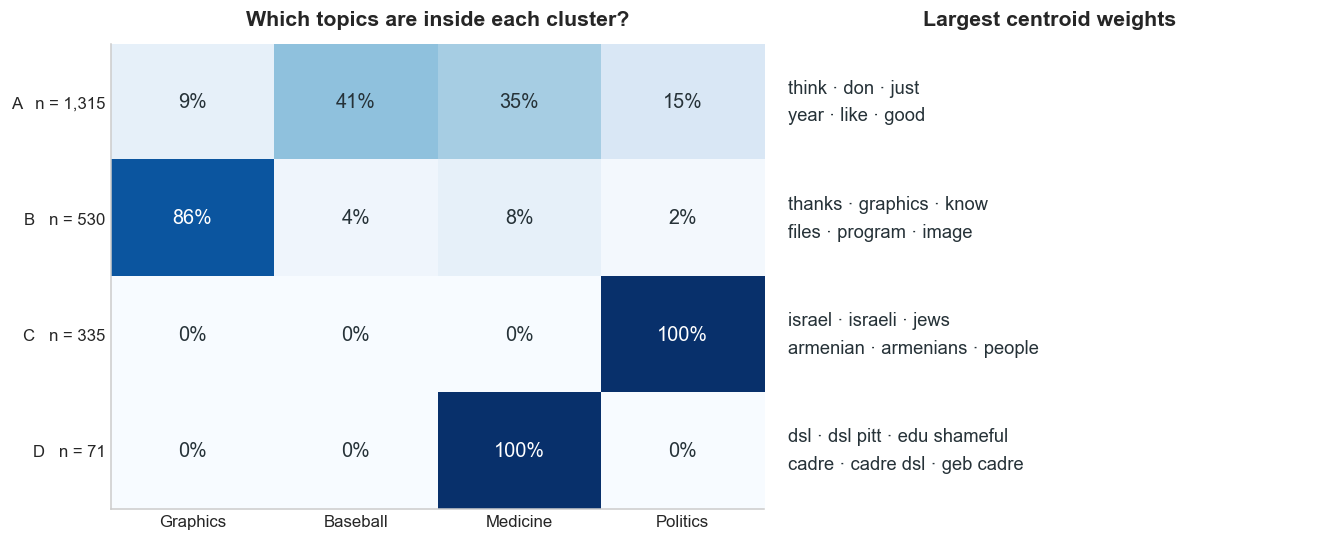

In [56]:
sizes = np.bincount(text_model.labels_, minlength=4)
cluster_order = np.argsort(-sizes)
cluster_letter = {cluster: 'ABCD'[row] for row, cluster in enumerate(cluster_order)}
composition = np.array([np.bincount(reference_topics[text_model.labels_ == cluster], minlength=4)
                        for cluster in cluster_order])
shares = composition / composition.sum(axis=1, keepdims=True)
fig, (heat, words) = plt.subplots(1, 2, figsize=(12, 4.8),
                                 gridspec_kw={'width_ratios': [1.2, 1]}, layout='constrained')
heat.imshow(shares, cmap='Blues', vmin=0, vmax=1, aspect='auto')
for row in range(4):
    for col in range(4):
        heat.text(col, row, f'{shares[row, col]:.0%}', ha='center', va='center',
                  fontsize=13, color='white' if shares[row, col] > .55 else INK)
heat.set(xticks=range(4), xticklabels=topic_names, yticks=range(4),
         yticklabels=[f'{cluster_letter[c]}   n = {sizes[c]:,}' for c in cluster_order],
         title='Which topics are inside each cluster?')
heat.grid(False)
words.set(xlim=(0, 1), ylim=(3.5, -.5), title='Largest centroid weights')
words.axis('off')
for row, cluster in enumerate(cluster_order):
    top = terms[text_model.cluster_centers_[cluster].argsort()[-6:][::-1]]
    words.text(.02, row, ' · '.join(top[:3]) + '\n' + ' · '.join(top[3:]),
               va='center', fontsize=12, linespacing=1.7, color=INK)
plt.show()

In [57]:
# These two short excerpts were selected to inspect the shared-signature cluster.
# Document IDs refer to the fetched, shuffled subset; contact details are omitted.
cards = []
for original_id in [7, 29]:
    row = np.flatnonzero(document_ids == original_id)[0]
    text = news.data[original_id]
    opening = ' '.join(text.split()[:11]) + ' …'
    tail = 'it is shameful to surrender it too soon.'
    ending = '… ' + tail if tail in text else '[no matching closing phrase]'
    cards.append(f'<div style="flex:1;min-width:240px;border-left:3px solid #8D99AE;'
                 f'padding:8px 16px"><b>Post {original_id} · cluster '
                 f'{cluster_letter[text_model.labels_[row]]}</b><p>{escape(opening)}</p>'
                 f'<p>{escape(ending)}</p></div>')
display(HTML('<div style="display:flex;gap:20px;flex-wrap:wrap">' + ''.join(cards) + '</div>'))
signature_cluster = text_model.cluster_centers_[:, vectorizer.vocabulary_['shameful']].argmax()
signature_ids = document_ids[text_model.labels_ == signature_cluster]
shared_signature = sum('shameful' in news.data[i] and 'surrender' in news.data[i] for i in signature_ids)
display(HTML(f'<details><summary><b>What connects these posts?</b></summary><p>'
             f'{shared_signature} of the {len(signature_ids)} posts in cluster '
             f'{cluster_letter[signature_cluster]} contain this repeated closing phrase. '
             f'The body topics differ, but a signature supplies several shared features. '
             f'The loader’s footer removal is heuristic; this signature survived. '
             f'K-means found a real pattern, but not necessarily the topic structure we wanted.</p></details>'))

A low objective is evidence of compact groups in **these features**, not evidence
that we discovered the right meaning of “similar.” The reference labels provide
another check, not an absolute definition of a good clustering.

The optional projection below compresses the fitted 2,000-dimensional space into
two dimensions. It is a view of the result, not the space in which we fitted k-means.

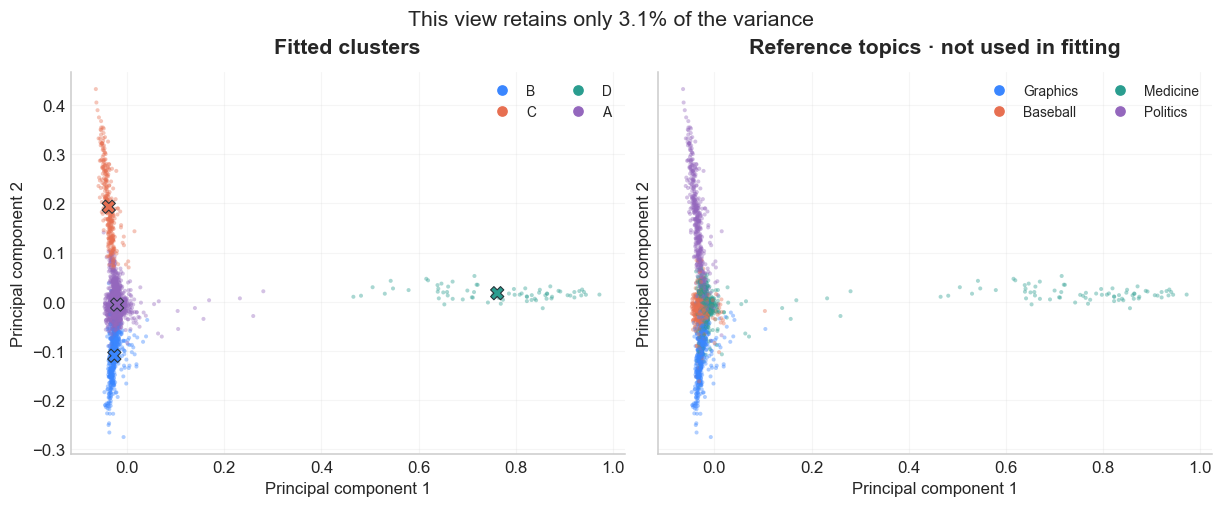

In [58]:
with threadpool_limits(limits=1):
    projection = PCA(n_components=2, svd_solver='randomized', random_state=42)
    X_2d = projection.fit_transform(X_text.toarray())
    centers_2d = projection.transform(text_model.cluster_centers_)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True, layout='constrained')
for ax, labels, title in zip(axes, [text_model.labels_, reference_topics],
                           ['Fitted clusters', 'Reference topics · not used in fitting']):
    ax.scatter(*X_2d.T, c=COLORS[labels], s=7, alpha=.4, edgecolors='none')
    ax.set(title=title, xlabel='Principal component 1', ylabel='Principal component 2')
axes[0].scatter(*centers_2d.T, c=COLORS[:4], marker='X', s=75, edgecolors=INK, linewidths=.7)
for ax, names in zip(axes, [[cluster_letter[c] for c in range(4)], topic_names]):
    ax.legend(handles=[Line2D([], [], marker='o', ls='', color=COLORS[c], label=name)
                       for c, name in enumerate(names)], fontsize=9, ncol=2, loc='upper right')
variance_kept = projection.explained_variance_ratio_.sum()
fig.suptitle(f'This view retains only {variance_kept:.1%} of the variance', fontsize=14)
plt.show()

## 6. How Many Groups Are Useful?

More centers give k-means more freedom. On the same points, a larger $k$ can split
an existing group and reduce cost without revealing a new kind of object.
The best achievable cost cannot increase with $k$; a particular run can still
get stuck at a poorer solution.

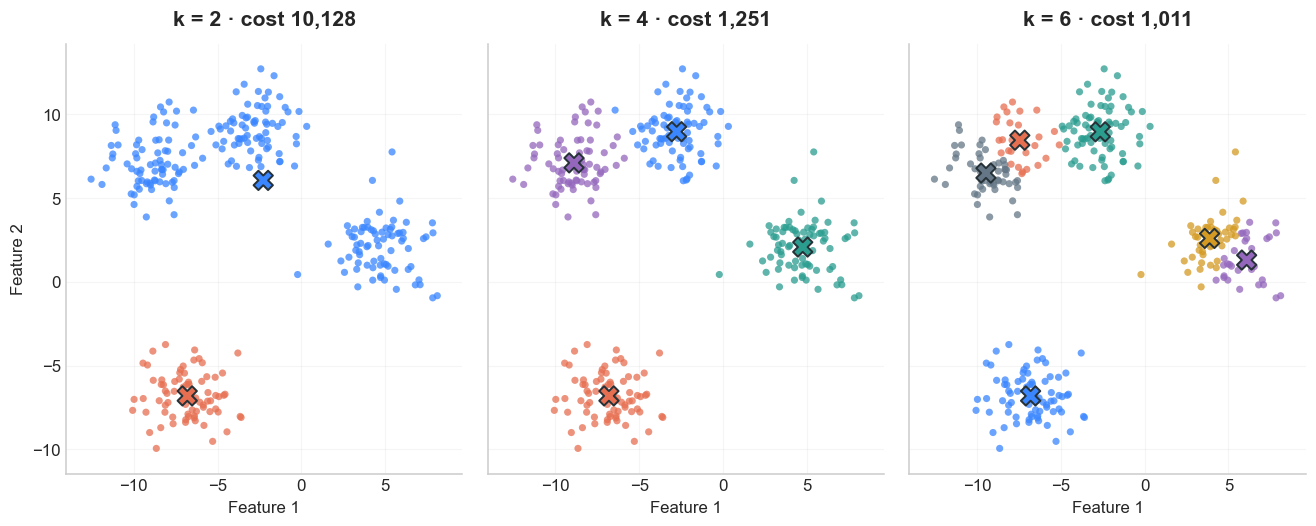

In [59]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4.5), sharex=True, sharey=True, layout='constrained')
with threadpool_limits(limits=1):
    for ax, k in zip(axes, [2, 4, 6]):
        model = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_simple)
        plot_groups(ax, X_simple, model.labels_, model.cluster_centers_)
        ax.set(title=f'k = {k} · cost {model.inertia_:,.0f}',
               xlim=(toy_limits[0][0], toy_limits[1][0]), ylim=(toy_limits[0][1], toy_limits[1][1]))
        if ax is not axes[0]:
            ax.set_ylabel('')
plt.show()

Now return to the posts. We'll compare cost and silhouette, using the same
1,000 sampled posts for every silhouette calculation and five
seeds at each $k$. Do these curves give us a convincing reason to prefer one $k$?

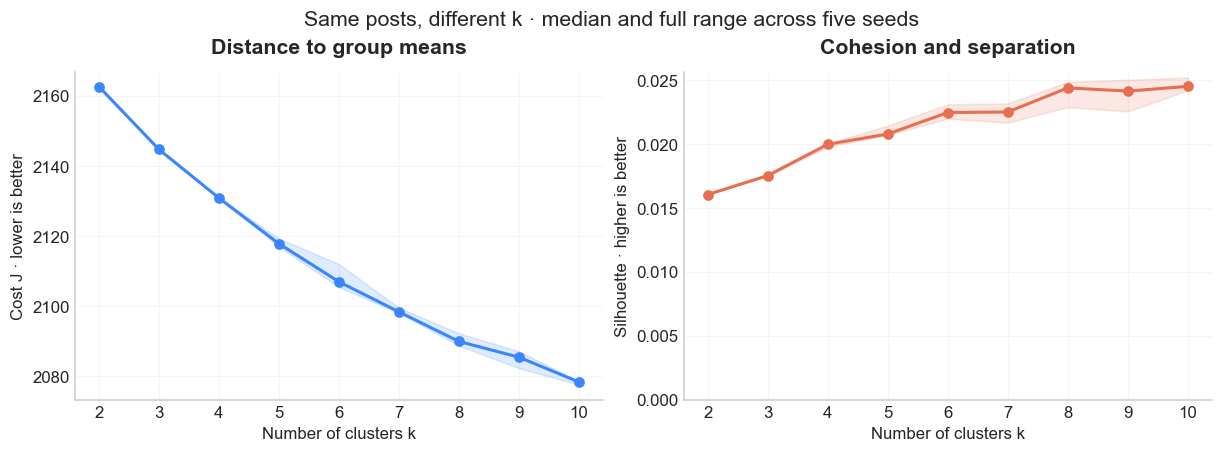

In [60]:
k_values = np.arange(2, 11)
silhouette_rows = np.random.default_rng(42).choice(len(document_ids), 1000, replace=False)
k_inertia = np.empty((len(k_values), 5))
k_silhouette = np.empty_like(k_inertia)
with threadpool_limits(limits=1):
    for row, k in enumerate(k_values):
        for seed in range(5):
            model = KMeans(n_clusters=k, n_init=10, random_state=seed).fit(X_text)
            k_inertia[row, seed] = model.inertia_
            k_silhouette[row, seed] = silhouette_score(
                X_text[silhouette_rows], model.labels_[silhouette_rows])
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout='constrained')
for ax, values, title, ylabel, color in zip(
        axes, [k_inertia, k_silhouette], ['Distance to group means', 'Cohesion and separation'],
        ['Cost J · lower is better', 'Silhouette · higher is better'], COLORS[:2]):
    ax.fill_between(k_values, values.min(axis=1), values.max(axis=1), color=color, alpha=.16)
    ax.plot(k_values, np.median(values, axis=1), 'o-', color=color, lw=2)
    ax.set(xlabel='Number of clusters k', ylabel=ylabel, title=title, xticks=k_values)
axes[1].set_ylim(bottom=0)
fig.suptitle('Same posts, different k · median and full range across five seeds', fontsize=14)
plt.show()

There is no clean verdict here. Cost keeps rewarding extra centers, while
silhouette remains low and depends on the solution reached. Four forum labels
do not force four compact groups in TF–IDF space. A useful choice of $k$ also needs
inspection of the groups and a purpose for using them.

## 7. When a Mean Is the Wrong Shape

K-means assigns a point to its nearest center. That makes straight decision
boundaries and convex Voronoi regions—even when the data follow a curved shape.
The pale backgrounds below show those regions; crosses mark the centers.

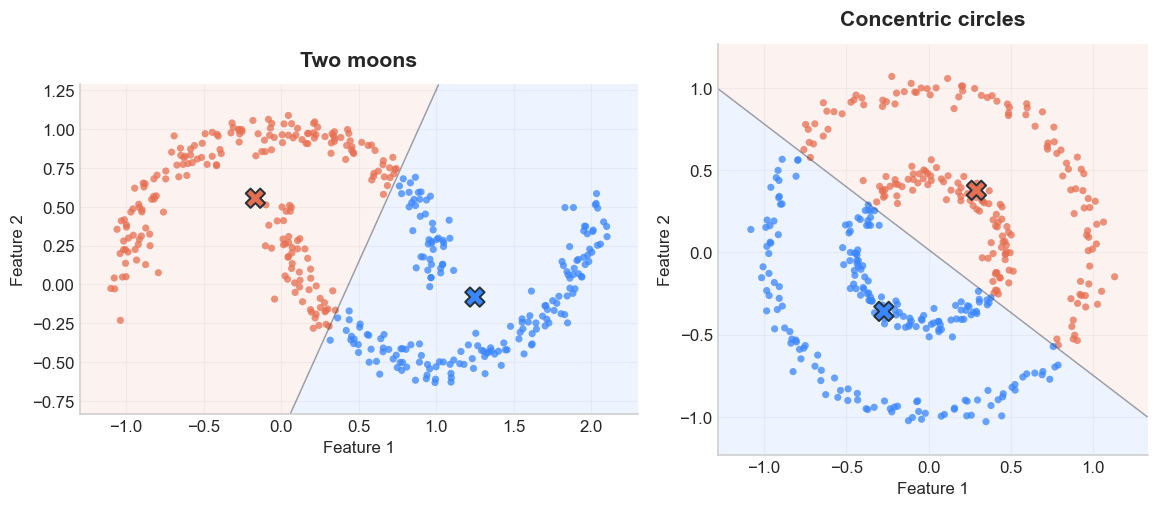

In [61]:
shape_examples = [('Two moons', make_moons(n_samples=400, noise=.065, random_state=42)),
                  ('Concentric circles', make_circles(n_samples=400, factor=.45,
                                                     noise=.045, random_state=42))]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), layout='constrained')
with threadpool_limits(limits=1):
    for ax, (title, (points, generating_labels)) in zip(axes, shape_examples):
        model = KMeans(n_clusters=2, n_init=10, random_state=42).fit(points)
        low, high = points.min(axis=0) - .2, points.max(axis=0) + .2
        xx, yy = np.meshgrid(np.linspace(low[0], high[0], 160), np.linspace(low[1], high[1], 160))
        distances = model.transform(np.c_[xx.ravel(), yy.ravel()]) ** 2
        margin = (distances[:, 0] - distances[:, 1]).reshape(xx.shape)
        ax.contourf(xx, yy, margin, levels=[margin.min() - 1, 0, margin.max() + 1],
                    cmap=ListedColormap(COLORS[:2]), alpha=.09)
        ax.contour(xx, yy, margin, levels=[0], colors=INK, linewidths=1, alpha=.4)
        plot_groups(ax, points, model.labels_, model.cluster_centers_)
        ax.set(title=title, xlim=(low[0], high[0]), ylim=(low[1], high[1]))
plt.show()

These are failures of the model's geometry, not problems that more iterations
can solve. Density-based or graph-based clustering can express different kinds
of groups. Changing feature scales also changes distances and therefore the
question k-means answers.

## 8. Can We Give K-Means a Better Start?

Better starting centers won't turn a straight boundary into a curve. But when
distance to a mean is a useful idea, can we avoid some of the poor solutions
from Section 3? Let's return to those same 300 points and keep $k=4$.

**K-means++** chooses the first center randomly. It then favors points that are
poorly represented by the centers already chosen: a candidate's probability is
proportional to $D(x)^2$, where $D(x)$ is its distance to the nearest chosen center.
Nearby points are less likely to get another center; uncovered regions get more
attention. Scikit-learn uses a greedy version that tries several candidates at
each step and keeps the one that reduces cost most.

Only the starting centers change below. Each fit gets one start (`n_init=1`),
then the same assign-and-average updates until convergence. The two maps show
one illustrative seed; the cost comparison includes all 100 seeds, not just
the example that looks convincing.

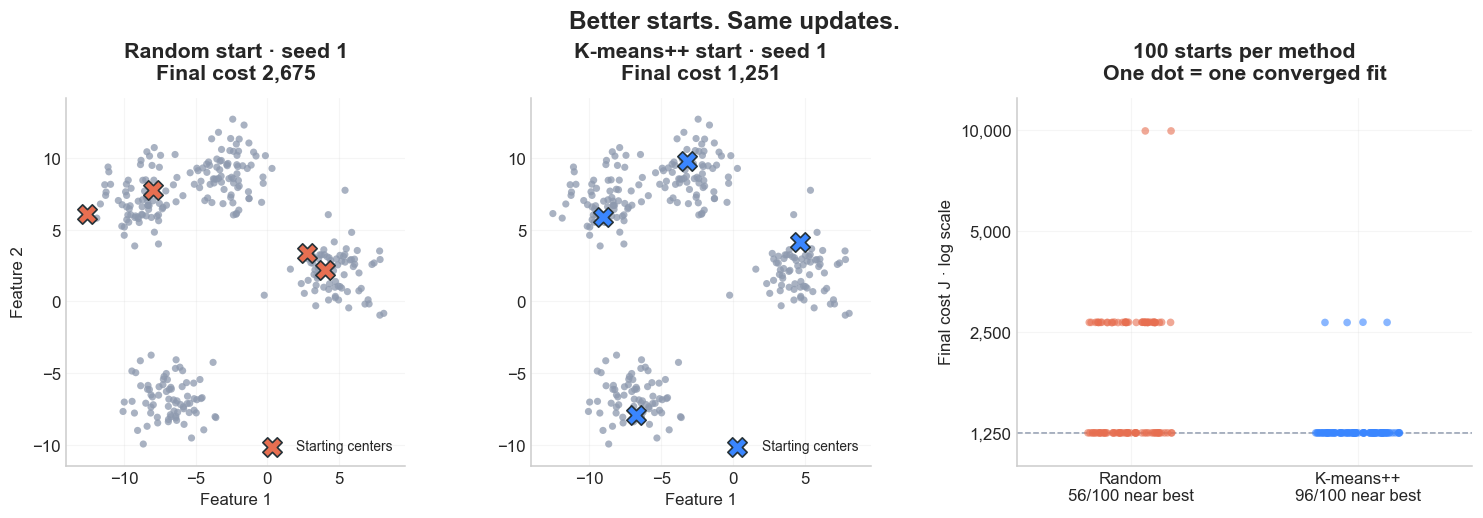

Near best = within 1% of the lowest cost observed here (1,251.4); this is an empirical comparison, not a proof of the global optimum.


In [62]:
initializations = {'Random': [], 'K-means++': []}
initialization_costs = {name: [] for name in initializations}
with threadpool_limits(limits=1):
    for seed in range(100):
        starts = {
            'Random': X_simple[np.random.RandomState(seed).choice(len(X_simple), 4, replace=False)],
            'K-means++': kmeans_plusplus(X_simple, n_clusters=4, random_state=seed)[0],
        }
        for name, centers in starts.items():
            model = KMeans(n_clusters=4, init=centers, n_init=1, algorithm='lloyd',
                           max_iter=300, tol=1e-8).fit(X_simple)
            initializations[name].append(centers)
            initialization_costs[name].append(model.inertia_)

initialization_costs = {name: np.array(costs) for name, costs in initialization_costs.items()}
best_observed_cost = min(costs.min() for costs in initialization_costs.values())
near_best_counts = {name: np.count_nonzero(costs <= 1.01 * best_observed_cost)
                    for name, costs in initialization_costs.items()}
example_seed = 1  # An illustrative failure of random seeding; frequencies use every seed.
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.6), layout='constrained')
for ax, (name, starts), color in zip(axes[:2], initializations.items(), [COLORS[1], COLORS[0]]):
    plot_groups(ax, X_simple)
    ax.scatter(*starts[example_seed].T, marker='X', s=160, c=color,
               edgecolors=INK, linewidths=1.1, zorder=5, label='Starting centers')
    ax.set(xlim=(toy_limits[0][0], toy_limits[1][0]), ylim=(toy_limits[0][1], toy_limits[1][1]),
           title=f'{name} start · seed {example_seed}\nFinal cost {initialization_costs[name][example_seed]:,.0f}')
    ax.legend(loc='lower right', fontsize=9)
axes[1].set_ylabel('')
jitter = np.random.default_rng(42).uniform(-.19, .19, 100)
for col, (name, trial_costs), color in zip(range(2), initialization_costs.items(), [COLORS[1], COLORS[0]]):
    axes[2].scatter(col + jitter, trial_costs, s=25, color=color, alpha=.6, edgecolors='none')
axes[2].axhline(best_observed_cost, color=MUTED, ls='--', lw=1, zorder=0)
axes[2].set(yscale='log', ylim=(1000, 12500), xlim=(-.5, 1.5),
            xticks=[0, 1], xticklabels=[f'{name}\n{near_best_counts[name]}/100 near best'
                                      for name in initialization_costs],
            yticks=[1250, 2500, 5000, 10000], yticklabels=['1,250', '2,500', '5,000', '10,000'],
            ylabel='Final cost J · log scale', title='100 starts per method\nOne dot = one converged fit')
axes[2].minorticks_off()
fig.suptitle('Better starts. Same updates.', fontsize=16, weight='bold')
plt.show()
print(f'Near best = within 1% of the lowest cost observed here ({best_observed_cost:,.1f}); '
      'this is an empirical comparison, not a proof of the global optimum.')

Better seeding makes a low-cost result more reliable here, but k-means++ can
still miss it. It changes where optimization begins, not the objective or the
shape of the groups K-means can express. `n_init=10` is a separate safeguard:
repeat the whole fit ten times and keep the lowest-cost result. We can use both.

## Wrap-Up

K-means alternates between nearest-center assignments and group means, reducing
squared distance until it settles. Its answer depends on the representation,
the number of centers, and the starting point. Better seeding and multiple starts help with optimization,
but they cannot decide what makes a group useful: our text example even found a
shared signature. Compare cost with silhouette, inspect the members, and ask
whether distance to a mean captures the structure you care about.

Sources: [20 Newsgroups](http://qwone.com/~jason/20Newsgroups/),
[TF–IDF implementation](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html),
[silhouette score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html),
[adjusted Rand index](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.adjusted_rand_score.html),
[k-means++ initialization](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.kmeans_plusplus.html).